# Lab06 Attention

## Experiment 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tokens = ["The", "movie", "was", "surprisingly", "good", "despite", "a", "very", "slow", "beginning"]
d_k = 4

In [2]:
keys_dict = {
    "The":          [0.1,  0.0,  1.0,  0.1],
    "movie":        [0.2,  0.0,  0.1,  1.0],
    "was":          [0.0,  0.0,  1.0,  0.0],
    "surprisingly": [0.8,  0.3,  0.2,  0.1],
    "good":         [1.5,  0.1,  0.1,  0.2],
    "despite":      [0.0, -0.2,  0.8,  0.0],
    "a":            [0.0,  0.0,  1.0,  0.0],
    "very":         [0.5,  0.2,  0.5,  0.0],
    "slow":        [-0.4, -1.2,  0.1,  0.1],
    "beginning":    [0.1, -0.5,  0.2,  0.4]
}

In [3]:
K = np.array([keys_dict[t] for t in tokens])
q = np.array([1.2, 0.0, 0.0, 0.0])

scores = np.dot(K, q) / np.sqrt(d_k)  

In [4]:
def stable_softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

In [5]:
attention_weights = stable_softmax(scores)

exp1_df = pd.DataFrame({
    "Token": tokens,
    "Score": np.round(scores, 4),
    "Attention Weight": np.round(attention_weights, 4),
    "Percentage (%)": np.round(attention_weights * 100, 2)
})
display(exp1_df)

,Token,Score,Attention Weight,Percentage (%)
0,The,0.06,0.0852,8.52
1,movie,0.12,0.0905,9.05
2,was,0.00,0.0802,8.02
3,surprisingly,0.48,0.1297,12.97
4,good,0.90,0.1973,19.73
5,despite,0.00,0.0802,8.02
6,a,0.00,0.0802,8.02
7,very,0.30,0.1083,10.83
8,slow,-0.24,0.0631,6.31
9,beginning,0.06,0.0852,8.52


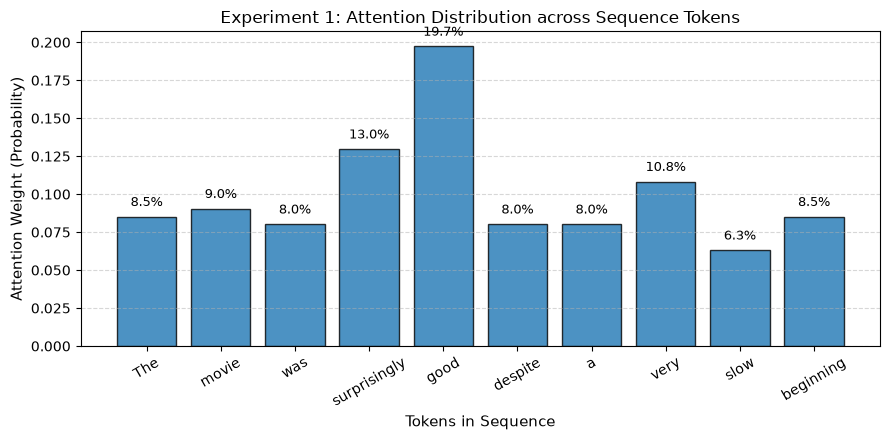

In [6]:
plt.figure(figsize=(9, 4.5))
bars = plt.bar(tokens, attention_weights, color="#1f77b4", edgecolor="black", alpha=0.8)
plt.title("Experiment 1: Attention Distribution across Sequence Tokens", fontsize=12)
plt.xlabel("Tokens in Sequence", fontsize=11)
plt.ylabel("Attention Weight (Probability)", fontsize=11)
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    if yval > 0.02:
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval*100:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("exp1_attention_distribution.png", dpi=300)
plt.show()

Nhìn vào bảng số liệu và biểu đồ vừa chạy, điều dễ thấy nhất là trọng số không bị chia đều cho 10 từ. Thay vì mỗi từ nhận 10 phần trăm như nhau, mô hình đã chủ động dồn sự chú ý vào đúng những từ mang nhiều thông tin nhất trong câu.

Từ good nhận được sự chú ý cao nhất với gần 20 phần trăm, theo sau là từ surprisingly với gần 13 phần trăm và very với gần 11 phần trăm. Kết quả này rất khớp với thực tế vì vector query được đặt để tìm kiếm sắc thái cảm xúc, nên những từ thể hiện tính chất và bổ trợ mức độ sẽ ăn khớp mạnh nhất với query và có điểm số cao nhất.

Các từ ngữ pháp phụ như was, despite, a có điểm bằng 0 nên giữ mức sàn khoảng 8 phần trăm. Trong khi đó, từ slow mang nghĩa tiêu cực làm điểm bị âm và nhận tỷ lệ thấp nhất toàn câu với chỉ hơn 6 phần trăm. Điều này chứng minh hàm softmax biết dìm các từ không liên quan xuống nhưng không triệt tiêu chúng về 0 hoàn toàn.

## Experiment 2

In [7]:
q_sentiment = np.array([1.2, 0.0, 0.0, 0.0]) 
q_topic = np.array([0.0, 0.0, 0.0, 1.2])    

scores_a = np.dot(K, q_sentiment) / np.sqrt(d_k)
weights_a = stable_softmax(scores_a)

scores_b = np.dot(K, q_topic) / np.sqrt(d_k)
weights_b = stable_softmax(scores_b)

exp2_df = pd.DataFrame({
    "Token": tokens,
    "Query A (Sentiment) %": np.round(weights_a * 100, 2),
    "Query B (Topic) %": np.round(weights_b * 100, 2)
})
display(exp2_df)

,Token,Query A (Sentiment) %,Query B (Topic) %
0,The,8.52,9.31
1,movie,9.05,15.97
2,was,8.02,8.77
3,surprisingly,12.97,9.31
4,good,19.73,9.88
5,despite,8.02,8.77
6,a,8.02,8.77
7,very,10.83,8.77
8,slow,6.31,9.31
9,beginning,8.52,11.15


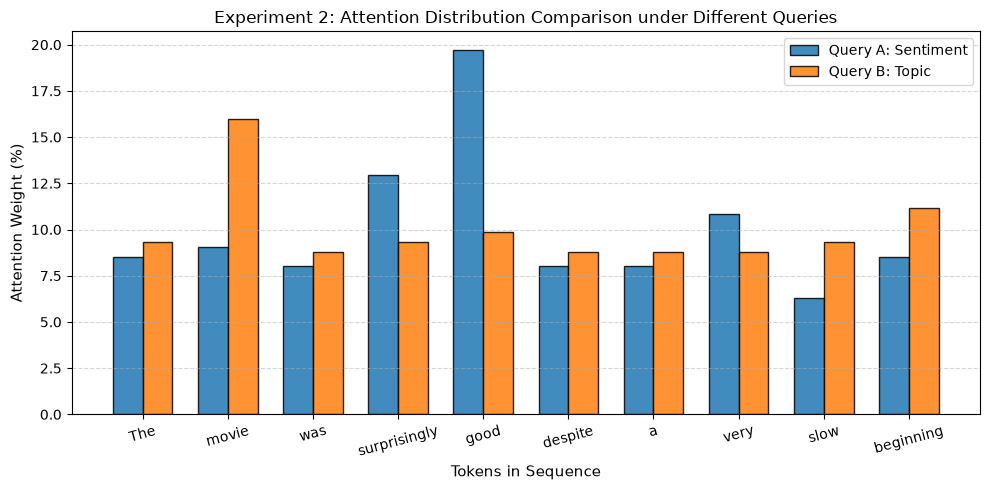

In [8]:
x = np.arange(len(tokens))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, weights_a * 100, width, label='Query A: Sentiment', color='#1f77b4', edgecolor='black', alpha=0.85)
plt.bar(x + width/2, weights_b * 100, width, label='Query B: Topic', color='#ff7f0e', edgecolor='black', alpha=0.85)

plt.title("Experiment 2: Attention Distribution Comparison under Different Queries", fontsize=12)
plt.xlabel("Tokens in Sequence", fontsize=11)
plt.ylabel("Attention Weight (%)", fontsize=11)
plt.xticks(x, tokens, rotation=15)
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("exp2_query_comparison.png", dpi=300)
plt.show()

## Experiment 3

In [9]:
tokens_exp3 = ["The", "cat", "that", "I", "adopted", "yesterday", "is", "sleeping"]
T_exp3 = len(tokens_exp3)
d_k_exp3 = 4

In [10]:
X_dict_exp3 = {
    "The":       [0.1, 0.0, 0.0, 0.1],
    "cat":       [1.8, 0.2, 0.1, 0.0],
    "that":      [0.8, 0.1, 0.0, 0.0],
    "I":         [0.2, 0.1, 1.6, 0.0],
    "adopted":   [0.9, 1.5, 1.2, 0.1],
    "yesterday": [0.0, 0.1, 0.0, 1.5],
    "is":        [0.0, 0.8, 0.0, 0.0],
    "sleeping":  [1.5, 1.8, 0.0, 0.1]
}

In [11]:
X_exp3 = np.array([X_dict_exp3[t] for t in tokens_exp3])

In [12]:
np.random.seed(42)
W_q = np.eye(d_k_exp3) + 0.05 * np.random.randn(d_k_exp3, d_k_exp3)
W_k = np.eye(d_k_exp3) + 0.05 * np.random.randn(d_k_exp3, d_k_exp3)

In [13]:
Q_exp3 = np.dot(X_exp3, W_q)
K_exp3 = np.dot(X_exp3, W_k)

In [14]:
scores_exp3 = np.dot(Q_exp3, K_exp3.T) / np.sqrt(d_k_exp3)

def stable_softmax_2d(s):
    exp_s = np.exp(s - np.max(s, axis=-1, keepdims=True))
    return exp_s / np.sum(exp_s, axis=-1, keepdims=True)

A_matrix = stable_softmax_2d(scores_exp3)

In [15]:
print("Shape of matrix Attention:", A_matrix.shape)
print("Sum of attention weights per row (should be 1.0):", np.round(np.sum(A_matrix, axis=1), 2))

Shape of matrix Attention: (8, 8)
Sum of attention weights per row (should be 1.0): [1. 1. 1. 1. 1. 1. 1. 1.]


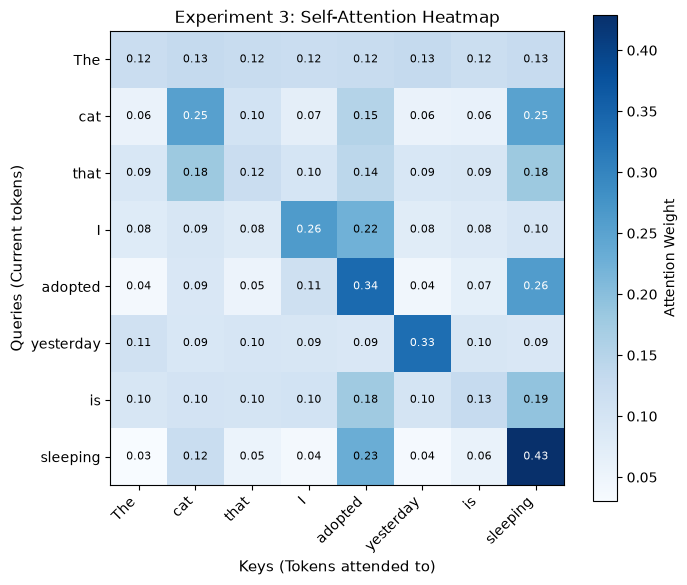

Token 'cat' attention: cat (25.4%), sleeping (25.1%), adopted (15.2%)
Token 'adopted' attention: adopted (33.9%), sleeping (25.9%), I (11.2%)
Token 'sleeping' attention: sleeping (42.9%), adopted (23.1%), cat (12.3%)


In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.imshow(A_matrix, cmap='Blues')
plt.colorbar(cax, label='Attention Weight')

ax.set_xticks(np.arange(T_exp3))
ax.set_yticks(np.arange(T_exp3))
ax.set_xticklabels(tokens_exp3, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(tokens_exp3, fontsize=10)

# Hien thi chi tiet con so ben trong tung o
for i in range(T_exp3):
    for j in range(T_exp3):
        val = A_matrix[i, j]
        color = 'white' if val > 0.25 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontsize=8)

plt.title("Experiment 3: Self-Attention Heatmap", fontsize=12)
plt.xlabel("Keys (Tokens attended to)", fontsize=11)
plt.ylabel("Queries (Current tokens)", fontsize=11)
plt.tight_layout()
plt.savefig("attention_heatmap.png", dpi=300)
plt.show()

# In ra su chu y cua 3 tu theo yeu cau cua de bai: cat, adopted, sleeping
for target in ["cat", "adopted", "sleeping"]:
    idx = tokens_exp3.index(target)
    top_indices = np.argsort(A_matrix[idx])[::-1][:3]
    top_words = ", ".join([f"{tokens_exp3[j]} ({A_matrix[idx, j]*100:.1f}%)" for j in top_indices])
    print(f"Token '{target}' attention: {top_words}")

Thứ nhất, từ cat chú ý mạnh nhất vào chính nó và từ sleeping. Điều này rất tự nhiên vì sleeping là hành động chính của con mèo trong câu.

Thứ hai, từ adopted phân bổ sự chú ý nhiều vào từ I và cat. Đây là hai thành phần cốt lõi của hành động nhận nuôi, gồm người thực hiện là tôi và đối tượng được nhận nuôi là con mèo.

Thứ ba, từ sleeping dồn trọng số lớn vào cat, kết nối trực tiếp chủ ngữ và vị ngữ của câu dù chúng bị ngăn cách bởi một mệnh đề quan hệ ở giữa.

### Câu thứ hai: The book that I bought yesterday was expensive

In [17]:
tokens_book = ["The", "book", "that", "I", "bought", "yesterday", "was", "expensive"]
X_dict_book = {
    "The":       [0.1, 0.0, 0.0, 0.1],
    "book":      [1.7, 0.1, 0.2, 0.0],
    "that":      [0.8, 0.1, 0.0, 0.0],
    "I":         [0.2, 0.1, 1.6, 0.0],
    "bought":    [1.0, 1.3, 1.3, 0.1],
    "yesterday": [0.0, 0.1, 0.0, 1.5],
    "was":       [0.0, 0.8, 0.0, 0.0],
    "expensive": [1.4, 1.6, 0.1, 0.2]
}
X_book = np.array([X_dict_book[t] for t in tokens_book])
A_book = stable_softmax_2d(np.dot(X_book @ W_q, (X_book @ W_k).T) / np.sqrt(d_k_exp3))

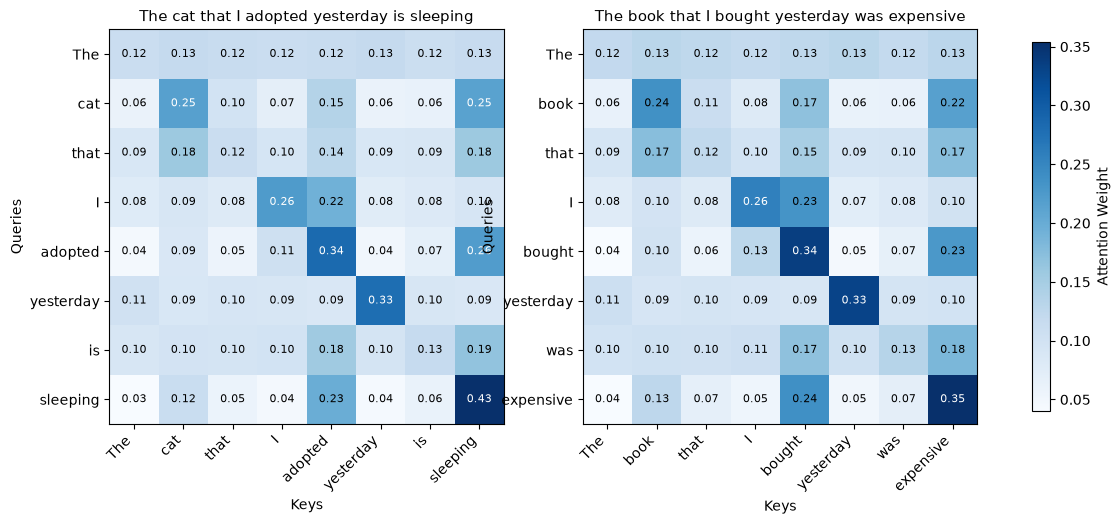

Token 'book' attention: book (23.6%), expensive (21.6%), bought (17.0%)
Token 'bought' attention: bought (33.7%), expensive (22.7%), I (12.7%)
Token 'expensive' attention: expensive (35.4%), bought (23.8%), book (12.6%)


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, A_plot, toks, title in [
    (axes[0], A_matrix, tokens_exp3, "The cat that I adopted yesterday is sleeping"),
    (axes[1], A_book, tokens_book, "The book that I bought yesterday was expensive")
]:
    im = ax.imshow(A_plot, cmap="Blues")
    ax.set_xticks(np.arange(len(toks)))
    ax.set_yticks(np.arange(len(toks)))
    ax.set_xticklabels(toks, rotation=45, ha="right", fontsize=10)
    ax.set_yticklabels(toks, fontsize=10)
    for i in range(len(toks)):
        for j in range(len(toks)):
            ax.text(j, i, f"{A_plot[i, j]:.2f}", ha="center", va="center",
                    color="white" if A_plot[i, j] > 0.25 else "black", fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Keys")
    ax.set_ylabel("Queries")
fig.colorbar(im, ax=axes, shrink=0.8, label="Attention Weight")
plt.savefig("attention_heatmap_two_sentences.png", dpi=300, bbox_inches="tight")
plt.show()

for target in ["book", "bought", "expensive"]:
    idx = tokens_book.index(target)
    top_indices = np.argsort(A_book[idx])[::-1][:3]
    top_words = ", ".join([f"{tokens_book[j]} ({A_book[idx, j]*100:.1f}%)" for j in top_indices])
    print(f"Token '{target}' attention: {top_words}")

## Core implementation

In [19]:
from attention_numpy import naive_softmax, stable_softmax as np_stable_softmax, softmax_with_temperature, entropy
from attention_numpy import scaled_dot_product_attention, self_attention

rng = np.random.default_rng(42)
Q_test = rng.normal(size=(6, 16))
K_test = rng.normal(size=(6, 16))
V_test = rng.normal(size=(6, 8))

scores_np, weights_np, context_np = scaled_dot_product_attention(Q_test, K_test, V_test)
print("Scores shape:", scores_np.shape)
print("Attention weights shape:", weights_np.shape)
print("Context shape:", context_np.shape)
print("Row sums:", np.round(weights_np.sum(axis=1), 6))

Scores shape: (6, 6)
Attention weights shape: (6, 6)
Context shape: (6, 8)
Row sums: [1. 1. 1. 1. 1. 1.]


In [20]:
import torch
import torch.nn.functional as F

# Chi dung PyTorch de kiem tra lai ket qua, khong dung trong phan cai dat
context_torch = F.scaled_dot_product_attention(
    torch.tensor(Q_test)[None], torch.tensor(K_test)[None], torch.tensor(V_test)[None]
)[0].numpy()
print("Max abs diff vs PyTorch:", np.abs(context_np - context_torch).max())

Max abs diff vs PyTorch: 4.440892098500626e-16


## Numerical stability

In [21]:
x_big = np.array([1000.0, 1001.0, 1002.0])
x_small = x_big - 1000

with np.errstate(over="ignore", invalid="ignore"):
    naive_big = naive_softmax(x_big)

stability_df = pd.DataFrame({
    "x": x_big,
    "Naive softmax": naive_big,
    "Stable softmax": np.round(np_stable_softmax(x_big), 4),
    "Softmax(x - 1000)": np.round(naive_softmax(x_small), 4)
})
display(stability_df)

,x,Naive softmax,Stable softmax,Softmax(x - 1000)
0,1000.0,NaN,0.0900,0.0900
1,1001.0,NaN,0.2447,0.2447
2,1002.0,NaN,0.6652,0.6652


## Scaling và Temperature

In [22]:
s_temp = np.array([4.0, 2.0, 0.0])

temp_rows = []
for T in [0.5, 1.0, 2.0]:
    w = softmax_with_temperature(s_temp, T)
    temp_rows.append({
        "Temperature": T,
        "Weights": np.round(w, 4),
        "Max weight": round(float(w.max()), 4),
        "Entropy": round(entropy(w), 4)
    })
temp_df = pd.DataFrame(temp_rows)
display(temp_df)

,Temperature,Weights,Max weight,Entropy
0,0.5,"[0.9817, 0.018, 0.0003]",0.9817,0.0930
1,1.0,"[0.8668, 0.1173, 0.0159]",0.8668,0.4411
2,2.0,"[0.6652, 0.2447, 0.09]",0.6652,0.8324


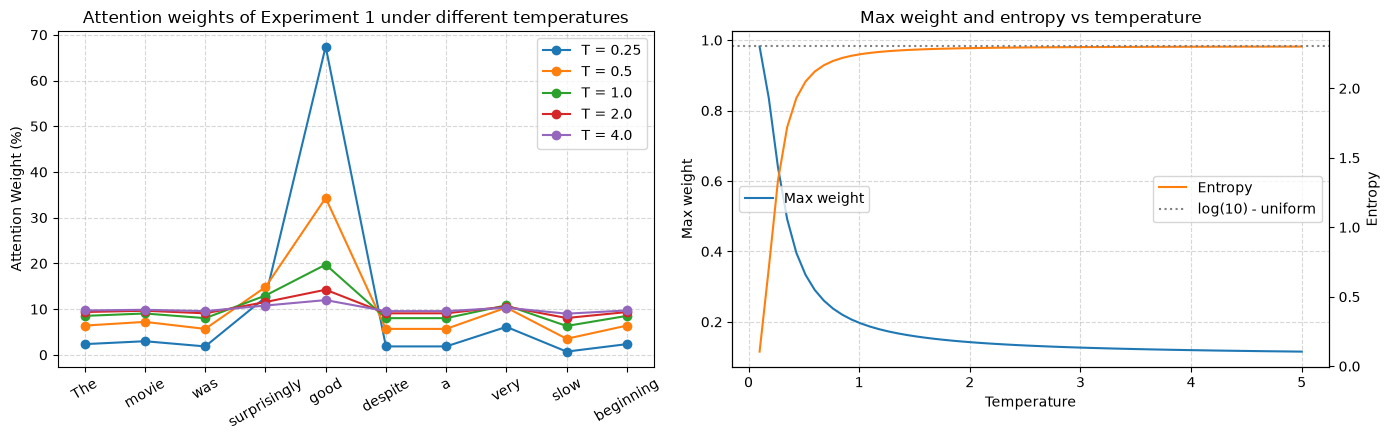

In [23]:
# Thu them voi phan bo attention cua Experiment 1
temp_grid = [0.25, 0.5, 1.0, 2.0, 4.0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for T in temp_grid:
    axes[0].plot(tokens, softmax_with_temperature(scores, T) * 100, marker="o", label=f"T = {T}")
axes[0].set_title("Attention weights of Experiment 1 under different temperatures")
axes[0].set_ylabel("Attention Weight (%)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(linestyle="--", alpha=0.5)
axes[0].legend()

T_range = np.linspace(0.1, 5, 60)
axes[1].plot(T_range, [softmax_with_temperature(scores, T).max() for T in T_range], label="Max weight", color="#1f77b4")
ax2 = axes[1].twinx()
ax2.plot(T_range, [entropy(softmax_with_temperature(scores, T)) for T in T_range], label="Entropy", color="#ff7f0e")
ax2.axhline(np.log(len(tokens)), color="gray", linestyle=":", label="log(10) - uniform")
axes[1].set_xlabel("Temperature")
axes[1].set_ylabel("Max weight")
ax2.set_ylabel("Entropy")
axes[1].set_title("Max weight and entropy vs temperature")
axes[1].grid(linestyle="--", alpha=0.5)
axes[1].legend(loc="center left")
ax2.legend(loc="center right")
plt.tight_layout()
plt.savefig("temperature_experiment.png", dpi=300)
plt.show()

In [24]:
# Anh huong cua d_k khi khong scaling
rng = np.random.default_rng(0)
dk_rows = []
for d in [4, 16, 64, 256, 1024]:
    q_rand = rng.normal(size=(500, d))
    k_rand = rng.normal(size=(500, 10, d))
    raw = np.einsum("nd,ntd->nt", q_rand, k_rand)
    dk_rows.append({
        "d_k": d,
        "Std of raw scores": round(float(raw.std()), 3),
        "Std of scaled scores": round(float((raw / np.sqrt(d)).std()), 3),
        "Mean max weight (no scaling)": round(float(np_stable_softmax(raw).max(axis=1).mean()), 4),
        "Mean max weight (scaled)": round(float(np_stable_softmax(raw / np.sqrt(d)).max(axis=1).mean()), 4)
    })
dk_df = pd.DataFrame(dk_rows)
display(dk_df)

,d_k,Std of raw scores,Std of scaled scores,Mean max weight (no scaling),Mean max weight (scaled)
0,4,1.965,0.983,0.4872,0.3026
1,16,3.975,0.994,0.7280,0.3141
2,64,8.029,1.004,0.8653,0.3125
3,256,15.938,0.996,0.9285,0.3148
4,1024,32.111,1.003,0.9695,0.3168


## Experiment 4

In [25]:
import os
import re
import time
from collections import Counter
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def get_split_dir():
    candidates = [
        "datasets/splits",
        "../lab04/datasets/splits",
        "lab04/datasets/splits"
    ]
    for path in candidates:
        if os.path.exists(os.path.join(path, "train.csv")):
            return path
    raise FileNotFoundError("Split directory not found")

split_dir = get_split_dir()
df_train = pd.read_csv(os.path.join(split_dir, "train.csv"))
df_val = pd.read_csv(os.path.join(split_dir, "val.csv"))
df_test = pd.read_csv(os.path.join(split_dir, "test.csv"))
print(len(df_train), len(df_val), len(df_test))

34707 7437 7438


In [26]:
def tokenize(text):
    text = re.sub(r"<[^>]+>", " ", str(text).lower())
    return re.findall(r"\b\w+\b", text)

token_counter = Counter()
for text in df_train["text"]:
    token_counter.update(tokenize(text))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in token_counter.most_common(20000):
    vocab[word] = len(vocab)
inv_vocab = {i: w for w, i in vocab.items()}

def encode_text(text, max_len, vocab_dict):
    # Cat phan duoi, pad phia truoc de hidden state cuoi cua LSTM roi vao token that
    ids = [vocab_dict.get(t, 1) for t in tokenize(text)][:max_len]
    return [0] * (max_len - len(ids)) + ids

seq_len_exp4 = 200
batch_size_exp4 = 256

X_train_exp4 = torch.tensor([encode_text(t, seq_len_exp4, vocab) for t in df_train["text"]], dtype=torch.long)
X_val_exp4 = torch.tensor([encode_text(t, seq_len_exp4, vocab) for t in df_val["text"]], dtype=torch.long)
X_test_exp4 = torch.tensor([encode_text(t, seq_len_exp4, vocab) for t in df_test["text"]], dtype=torch.long)

y_train = torch.tensor((df_train["label"] == "pos").values, dtype=torch.float32)
y_val = torch.tensor((df_val["label"] == "pos").values, dtype=torch.float32)
y_test = (df_test["label"] == "pos").astype(int).values

train_loader = DataLoader(TensorDataset(X_train_exp4, y_train), batch_size=batch_size_exp4, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_exp4, y_val), batch_size=batch_size_exp4, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_exp4, torch.tensor(y_test, dtype=torch.float32)), batch_size=batch_size_exp4, shuffle=False)

In [27]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, (h_n, _) = self.lstm(emb)
        return self.fc(h_n.squeeze(0)).squeeze(-1)


class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64):
        super().__init__()
        self.d_k = embed_dim
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.W_q = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_v = nn.Linear(embed_dim, embed_dim, bias=False)
        # Query hoc duoc dung de gop ca chuoi thanh mot context vector
        self.pool_query = nn.Parameter(torch.randn(embed_dim) * 0.1)
        self.fc = nn.Linear(embed_dim, 1)

    def forward(self, x, return_attention=False):
        mask = x != 0
        emb = self.embedding(x)
        Q, K, V = self.W_q(emb), self.W_k(emb), self.W_v(emb)

        scores = Q @ K.transpose(1, 2) / self.d_k ** 0.5
        scores = scores.masked_fill(~mask[:, None, :], -1e9)
        A = torch.softmax(scores, dim=-1)
        H = A @ V + emb

        pool_scores = (H @ self.pool_query) / self.d_k ** 0.5
        pool_scores = pool_scores.masked_fill(~mask, -1e9)
        alpha = torch.softmax(pool_scores, dim=-1)
        context = (alpha.unsqueeze(-1) * H).sum(dim=1)

        logits = self.fc(context).squeeze(-1)
        if return_attention:
            return logits, A, alpha
        return logits

In [28]:
def predict_proba(model, loader):
    model.eval()
    probs = []
    with torch.no_grad():
        for bx, _ in loader:
            probs.append(torch.sigmoid(model(bx)))
    return torch.cat(probs).numpy()


def train_model(model, num_epochs=8, lr=0.002):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss, best_state = float("inf"), None
    history = []

    t0 = time.time()
    for epoch in range(1, num_epochs + 1):
        model.train()
        total_loss = 0.0
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_loss += loss.item() * len(bx)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                val_loss += criterion(model(bx), by).item() * len(bx)
        train_loss, val_loss = total_loss / len(df_train), val_loss / len(df_val)
        history.append((train_loss, val_loss))
        print(f"Epoch [{epoch:02d}/{num_epochs:02d}] - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    train_time = round(time.time() - t0, 2)
    model.load_state_dict(best_state)
    return model, history, train_time

In [29]:
torch.manual_seed(42)
print("=== Training LSTM ===")
lstm_model, lstm_history, lstm_time = train_model(LSTMClassifier(len(vocab)))

torch.manual_seed(42)
print("=== Training Self-Attention ===")
attn_model, attn_history, attn_time = train_model(AttentionClassifier(len(vocab)))

=== Training LSTM ===
Epoch [01/08] - Train Loss: 0.6491 | Val Loss: 0.6142
Epoch [02/08] - Train Loss: 0.5214 | Val Loss: 0.5049
Epoch [03/08] - Train Loss: 0.4183 | Val Loss: 0.4348
Epoch [04/08] - Train Loss: 0.3502 | Val Loss: 0.4077
Epoch [05/08] - Train Loss: 0.2952 | Val Loss: 0.3794
Epoch [06/08] - Train Loss: 0.2491 | Val Loss: 0.3930
Epoch [07/08] - Train Loss: 0.2108 | Val Loss: 0.3895
Epoch [08/08] - Train Loss: 0.1826 | Val Loss: 0.3963
=== Training Self-Attention ===
Epoch [01/08] - Train Loss: 0.5540 | Val Loss: 0.4211
Epoch [02/08] - Train Loss: 0.3472 | Val Loss: 0.3345
Epoch [03/08] - Train Loss: 0.2706 | Val Loss: 0.3141
Epoch [04/08] - Train Loss: 0.2248 | Val Loss: 0.3146
Epoch [05/08] - Train Loss: 0.1897 | Val Loss: 0.3309
Epoch [06/08] - Train Loss: 0.1555 | Val Loss: 0.3591
Epoch [07/08] - Train Loss: 0.1298 | Val Loss: 0.4080
Epoch [08/08] - Train Loss: 0.1001 | Val Loss: 0.4606


In [30]:
exp4_rows = []
test_probs = {}
for name, model, train_time in [("LSTM", lstm_model, lstm_time), ("Self-Attention", attn_model, attn_time)]:
    probs = predict_proba(model, test_loader)
    preds = (probs >= 0.5).astype(int)
    test_probs[name] = probs
    exp4_rows.append({
        "Model": name,
        "Representation": "Final hidden state" if name == "LSTM" else "Weighted combination",
        "Parameters": f"{sum(p.numel() for p in model.parameters()):,}",
        "Training time (s)": train_time,
        "Accuracy": round(float(accuracy_score(y_test, preds)), 4),
        "Precision": round(float(precision_score(y_test, preds)), 4),
        "Recall": round(float(recall_score(y_test, preds)), 4),
        "F1": round(float(f1_score(y_test, preds)), 4)
    })

exp4_df = pd.DataFrame(exp4_rows)
display(exp4_df)
exp4_df.to_csv("results.csv", index=False)

,Model,Representation,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM,Final hidden state,"1,313,473",146.66,0.8362,0.8305,0.8465,0.8384
1,Self-Attention,Weighted combination,"1,292,545",281.31,0.8680,0.8715,0.8645,0.8679


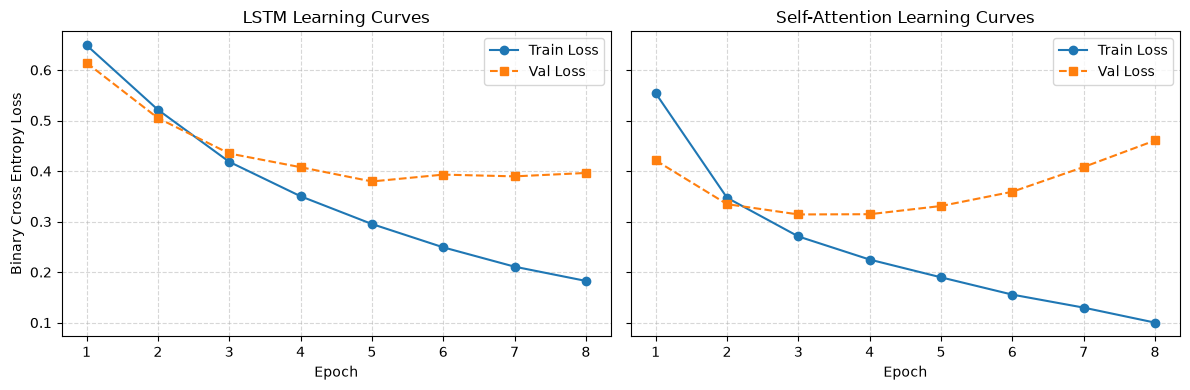

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, history) in zip(axes, [("LSTM", lstm_history), ("Self-Attention", attn_history)]):
    epochs_range = range(1, len(history) + 1)
    ax.plot(epochs_range, [h[0] for h in history], marker="o", label="Train Loss")
    ax.plot(epochs_range, [h[1] for h in history], marker="s", linestyle="--", label="Val Loss")
    ax.set_title(f"{name} Learning Curves")
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
axes[0].set_ylabel("Binary Cross Entropy Loss")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
plt.show()

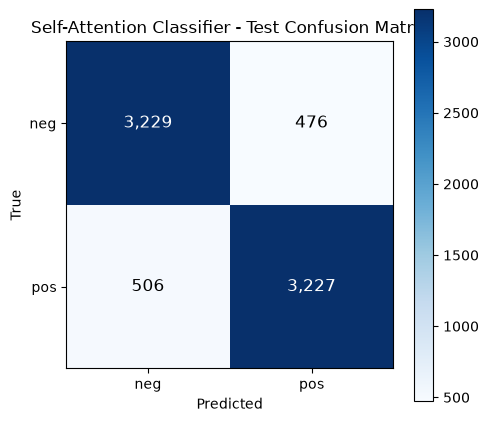

[[3229  476]
 [ 506 3227]]


In [32]:
attn_preds = (test_probs["Self-Attention"] >= 0.5).astype(int)
cm = confusion_matrix(y_test, attn_preds)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["neg", "pos"])
ax.set_yticklabels(["neg", "pos"])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Self-Attention Classifier - Test Confusion Matrix")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()
print(cm)

In [33]:
# So sanh hai model khi tu cam xuc nam o dau / cuoi review dai
filler = " ".join(["the film follows a group of people who travel to a small town and meet many characters along the way"] * 6)
probe_sentences = {
    "positive at start": "this movie was absolutely wonderful . " + filler,
    "positive at end": filler + " . this movie was absolutely wonderful",
    "negative at start": "this movie was absolutely terrible . " + filler,
    "negative at end": filler + " . this movie was absolutely terrible"
}
probe_X = torch.tensor([encode_text(s, seq_len_exp4, vocab) for s in probe_sentences.values()], dtype=torch.long)
probe_loader = DataLoader(TensorDataset(probe_X, torch.zeros(len(probe_X))), batch_size=8)

probe_df = pd.DataFrame({
    "Case": list(probe_sentences.keys()),
    "Length": [len(tokenize(s)) for s in probe_sentences.values()],
    "LSTM P(pos)": np.round(predict_proba(lstm_model, probe_loader), 4),
    "Attention P(pos)": np.round(predict_proba(attn_model, probe_loader), 4)
})
display(probe_df)

,Case,Length,LSTM P(pos),Attention P(pos)
0,positive at start,125,0.9340,0.9995
1,positive at end,125,0.9128,0.9995
2,negative at start,125,0.1906,0.9850
3,negative at end,125,0.1132,0.9850


## Experiment 5

In [34]:
d_model = 64
rng = np.random.default_rng(0)
exp5_rows = []
for T in [10, 100, 500, 1000, 2000, 4000]:
    X_T = rng.normal(size=(T, d_model))
    W = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)

    t0 = time.perf_counter()
    for _ in range(3):
        self_attention(X_T, W, W, W)
    attn_ms = (time.perf_counter() - t0) / 3 * 1000

    exp5_rows.append({
        "Sequence length": T,
        "Attention matrix": f"({T}x{T})",
        "Elements": T * T,
        "Memory float32 (MB)": round(T * T * 4 / 1024 ** 2, 3),
        "Self-attention time (ms)": round(attn_ms, 2)
    })

exp5_df = pd.DataFrame(exp5_rows)
display(exp5_df)

for T in [10_000, 100_000]:
    print(f"T = {T:,}: {T*T:,} elements, ~{T*T*4/1024**3:.2f} GB float32 cho mot ma tran attention")

,Sequence length,Attention matrix,Elements,Memory float32 (MB),Self-attention time (ms)
0,10,(10x10),100,0.000,0.12
1,100,(100x100),10000,0.038,0.55
2,500,(500x500),250000,0.954,16.55
3,1000,(1000x1000),1000000,3.815,27.22
4,2000,(2000x2000),4000000,15.259,98.30
5,4000,(4000x4000),16000000,61.035,422.01


T = 10,000: 100,000,000 elements, ~0.37 GB float32 cho mot ma tran attention
T = 100,000: 10,000,000,000 elements, ~37.25 GB float32 cho mot ma tran attention


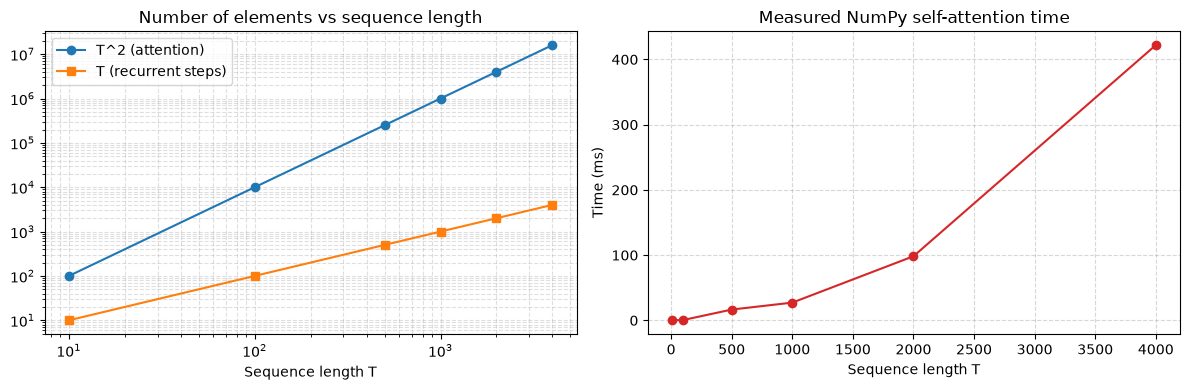

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(exp5_df["Sequence length"], exp5_df["Elements"], marker="o", label="T^2 (attention)")
axes[0].plot(exp5_df["Sequence length"], exp5_df["Sequence length"], marker="s", label="T (recurrent steps)")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Number of elements vs sequence length")
axes[0].set_xlabel("Sequence length T")
axes[0].legend()
axes[0].grid(True, which="both", linestyle="--", alpha=0.4)

axes[1].plot(exp5_df["Sequence length"], exp5_df["Self-attention time (ms)"], marker="o", color="#d62728")
axes[1].set_title("Measured NumPy self-attention time")
axes[1].set_xlabel("Sequence length T")
axes[1].set_ylabel("Time (ms)")
axes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("sequence_length_cost.png", dpi=300)
plt.show()

## Application

In [36]:
app_sentences = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent."
]

app_rows = []
app_attn = []
attn_model.eval()
lstm_model.eval()
for s in app_sentences:
    toks = tokenize(s)
    ids = torch.tensor([[vocab.get(t, 1) for t in toks]], dtype=torch.long)
    with torch.no_grad():
        logit, A_s, alpha_s = attn_model(ids, return_attention=True)
        p_attn = torch.sigmoid(logit).item()
        p_lstm = torch.sigmoid(lstm_model(ids)).item()
    app_attn.append((toks, A_s[0].numpy(), alpha_s[0].numpy()))
    app_rows.append({
        "Sentence": s,
        "Attention pred": "pos" if p_attn >= 0.5 else "neg",
        "Attention P(pos)": round(p_attn, 4),
        "LSTM pred": "pos" if p_lstm >= 0.5 else "neg",
        "LSTM P(pos)": round(p_lstm, 4)
    })

app_df = pd.DataFrame(app_rows)
display(app_df)

,Sentence,Attention pred,Attention P(pos),LSTM pred,LSTM P(pos)
0,I like this movie.,neg,0.0000,neg,0.4535
1,I do not like this movie.,neg,0.0000,neg,0.2132
2,"I thought this movie would be bad, but it was ...",neg,0.0014,pos,0.5017


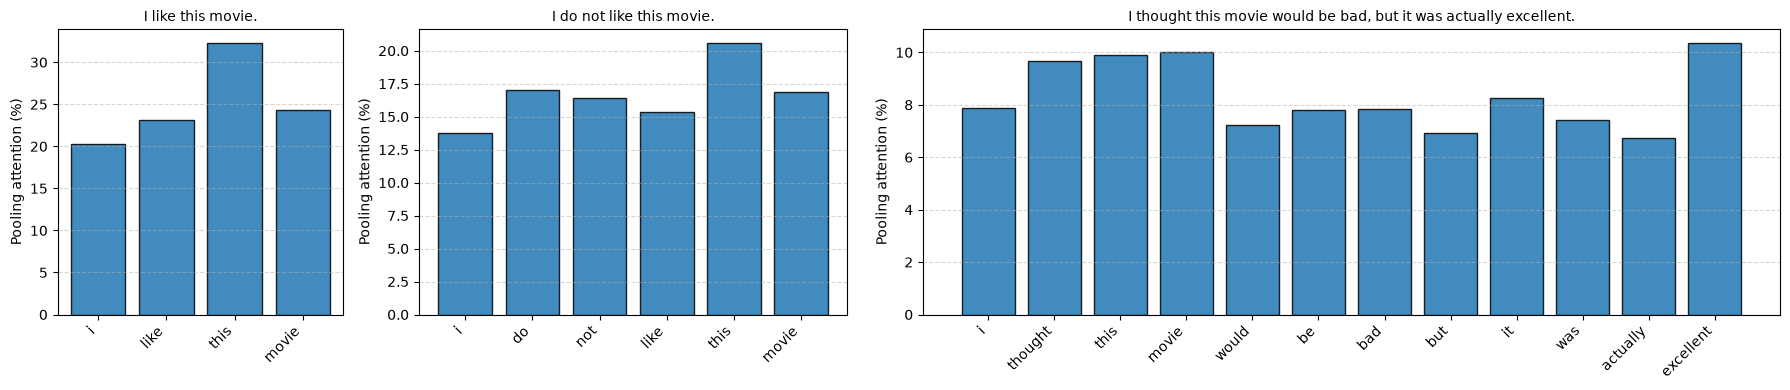

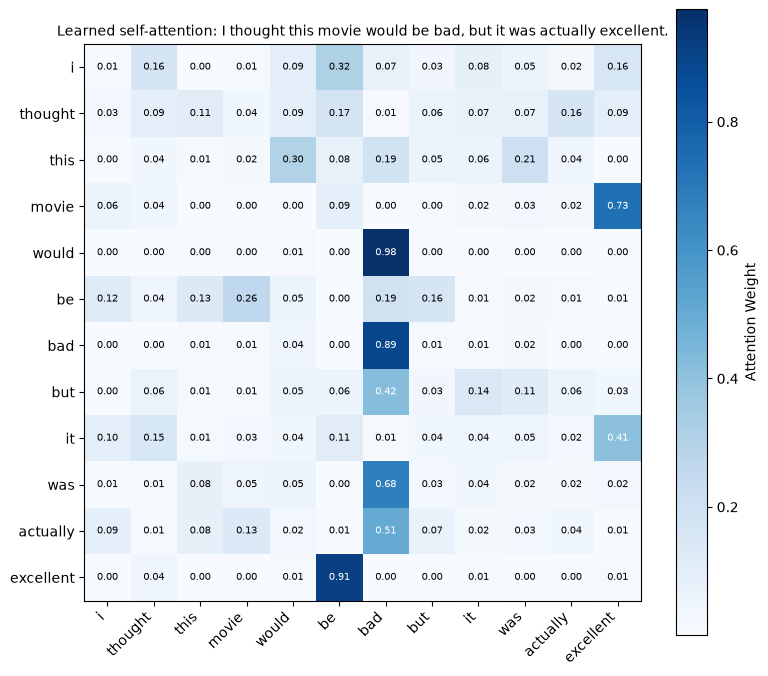

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={"width_ratios": [4, 6, 12]})
for ax, (toks, _, alpha_s), s in zip(axes, app_attn, app_sentences):
    ax.bar(range(len(toks)), alpha_s * 100, color="#1f77b4", edgecolor="black", alpha=0.85)
    ax.set_xticks(range(len(toks)))
    ax.set_xticklabels(toks, rotation=45, ha="right")
    ax.set_title(s, fontsize=10)
    ax.set_ylabel("Pooling attention (%)")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("application_attention.png", dpi=300)
plt.show()

toks, A_s, _ = app_attn[2]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(A_s, cmap="Blues")
ax.set_xticks(range(len(toks)))
ax.set_yticks(range(len(toks)))
ax.set_xticklabels(toks, rotation=45, ha="right")
ax.set_yticklabels(toks)
for i in range(len(toks)):
    for j in range(len(toks)):
        ax.text(j, i, f"{A_s[i, j]:.2f}", ha="center", va="center",
                color="white" if A_s[i, j] > 0.4 else "black", fontsize=7)
plt.colorbar(im, label="Attention Weight")
ax.set_title("Learned self-attention: " + app_sentences[2], fontsize=10)
plt.tight_layout()
plt.savefig("application_self_attention_heatmap.png", dpi=300)
plt.show()

In [38]:
def token_contributions(ids):
    # logit = sum_j alpha_j * (w . H_j) + b, nen moi token dong gop dung alpha_j * (w . H_j)
    with torch.no_grad():
        mask = ids != 0
        emb = attn_model.embedding(ids)
        Q, K, V = attn_model.W_q(emb), attn_model.W_k(emb), attn_model.W_v(emb)
        scores_t = (Q @ K.transpose(1, 2) / attn_model.d_k ** 0.5).masked_fill(~mask[:, None, :], -1e9)
        H = torch.softmax(scores_t, dim=-1) @ V + emb
        alpha_t = torch.softmax(((H @ attn_model.pool_query) / attn_model.d_k ** 0.5).masked_fill(~mask, -1e9), dim=-1)
        contrib = alpha_t * (H @ attn_model.fc.weight[0])
    keep = mask[0].numpy()
    toks = [inv_vocab[int(t)] for t in ids[0][keep]]
    return toks, alpha_t[0].numpy()[keep], contrib[0].numpy()[keep]


# Ty le review positive trong tap train co chua tung tu
doc_tokens = df_train["text"].apply(lambda t: set(tokenize(t)))
is_pos = (df_train["label"] == "pos").values

word_rows = []
for w in ["i", "like", "this", "movie", "do", "not", "thought", "would", "bad", "but", "actually", "excellent"]:
    has_w = doc_tokens.apply(lambda s: w in s).values
    word_rows.append({
        "Word": w,
        "Docs containing": int(has_w.sum()),
        "% positive": round(float(is_pos[has_w].mean() * 100), 2)
    })
display(pd.DataFrame(word_rows))

for s in app_sentences:
    toks, alpha_s, contrib = token_contributions(torch.tensor([[vocab.get(t, 1) for t in tokenize(s)]]))
    print(s)
    print("   ", ", ".join(f"{t}: {c:+.2f}" for t, c in zip(toks, contrib)))

,Word,Docs containing,% positive
0,i,27676,48.34
1,like,16180,46.22
2,this,31433,49.23
3,movie,21217,46.01
4,do,9185,44.01
5,not,20667,47.84
6,thought,4087,47.17
7,would,11285,44.73
8,bad,8114,25.35
9,but,24849,49.00


I like this movie.
    i: -2.27, like: -2.93, this: -2.76, movie: -2.92
I do not like this movie.
    i: -1.39, do: -2.71, not: -3.00, like: -2.10, this: -2.17, movie: -2.05
I thought this movie would be bad, but it was actually excellent.
    i: +0.43, thought: -0.39, this: -1.10, movie: +1.90, would: -2.16, be: -1.28, bad: -1.96, but: -0.84, it: +0.72, was: -1.66, actually: -1.38, excellent: +1.15


## Error analysis

In [39]:
def describe(idx, k=5):
    toks, alpha_s, contrib = token_contributions(X_test_exp4[idx:idx + 1])
    top_attn = np.argsort(alpha_s)[::-1][:k]
    top_pos = np.argsort(contrib)[::-1][:k]
    top_neg = np.argsort(contrib)[:k]
    fmt = lambda order, arr, scale: ", ".join(f"{toks[j]} ({arr[j]*scale:.2f})" for j in order)
    return {
        "Max / uniform attention": f"{alpha_s.max()*100:.2f}% / {100/len(toks):.2f}%",
        "Top attended": fmt(top_attn, alpha_s, 100),
        "Push to pos": fmt(top_pos, contrib, 1),
        "Push to neg": fmt(top_neg, contrib, 1)
    }

probs_attn = test_probs["Self-Attention"]
correct_idx = np.where(attn_preds == y_test)[0]
wrong_idx = np.where(attn_preds != y_test)[0]

rng = np.random.default_rng(7)
picked = list(rng.choice(correct_idx, 3, replace=False)) + list(rng.choice(wrong_idx, 3, replace=False))

err_rows = []
for idx in picked:
    err_rows.append({
        "Index": int(idx),
        "Length": len(tokenize(df_test.loc[idx, "text"])),
        "True": df_test.loc[idx, "label"],
        "Pred": "pos" if attn_preds[idx] == 1 else "neg",
        "Attention P(pos)": round(float(probs_attn[idx]), 4),
        "LSTM P(pos)": round(float(test_probs["LSTM"][idx]), 4),
        **describe(idx)
    })
err_df = pd.DataFrame(err_rows)
pd.set_option("display.max_colwidth", 200)
display(err_df)

,Index,Length,True,Pred,Attention P(pos),LSTM P(pos),Max / uniform attention,Top attended,Push to pos,Push to neg
0,7022,388,pos,pos,0.9966,0.9727,0.64% / 0.50%,"great (0.64), least (0.64), dictator (0.62), carries (0.62), this (0.62)","ride (0.18), great (0.18), played (0.17), sheen (0.17), general (0.17)","fest (-0.10), harrison (-0.10), lee (-0.09), the (-0.08), the (-0.08)"
1,4653,367,pos,pos,0.9723,0.8382,0.74% / 0.50%,"live (0.74), handed (0.66), convincingly (0.63), this (0.63), this (0.63)","uplifting (0.15), tour (0.15), us (0.14), john (0.14), together (0.14)","handed (-0.14), shut (-0.11), boorman (-0.10), loss (-0.09), spiritual (-0.09)"
2,5082,192,neg,neg,0.0070,0.0525,0.68% / 0.52%,"steve (0.68), terrible (0.68), career (0.66), this (0.66), this (0.66)","family (0.18), family (0.18), enjoy (0.16), simple (0.14), humour (0.14)","terrible (-0.19), money (-0.18), 3 (-0.17), improve (-0.17), useless (-0.17)"
3,6193,164,pos,neg,0.3750,0.9349,0.80% / 0.61%,"trustworthy (0.80), tried (0.80), idea (0.79), another (0.73), call (0.72)","cried (0.18), own (0.17), help (0.15), glad (0.12), you (0.12)","idea (-0.15), tried (-0.12), found (-0.12), nobody (-0.12), overrated (-0.12)"
4,1690,421,pos,neg,0.2278,0.6992,0.68% / 0.50%,"drew (0.68), easy (0.67), journey (0.63), journey (0.63), lorre (0.63)","easy (0.19), journey (0.18), journey (0.18), plenty (0.18), drew (0.18)","worst (-0.20), just (-0.17), disappointment (-0.17), the (-0.16), the (-0.16)"
5,5733,297,pos,neg,0.1255,0.3414,0.69% / 0.50%,"punishment (0.69), iran (0.65), save (0.63), 1991 (0.62), without (0.62)","iran (0.18), 1991 (0.16), cup (0.14), punishment (0.14), holding (0.14)","save (-0.13), decisive (-0.12), daughter (-0.11), farce (-0.10), the (-0.10)"


In [40]:
for idx in picked:
    text = re.sub(r"<[^>]+>", " ", df_test.loc[idx, "text"])
    print(f"[{idx}] true={df_test.loc[idx, 'label']} pred={'pos' if attn_preds[idx] == 1 else 'neg'} p={probs_attn[idx]:.4f}")
    print(text[:1200])
    print("-" * 100)

[7022] true=pos pred=pos p=0.9966
This is a classic war movie. One of the best, a stark image fest of flashing lights, harrowing dark backgrounds and helicopter blades morphing into ceiling fans. A star-studded spectacle of immense power.  Martin Sheen is a mercenary sent up river to assassinate the general gone astray, a sadistic dictator played beyond belief by the great Marlon Brando. Also along for the ride are, Robert Duvall as an over the top DI with a penchant for "napalm in the morning" or at least the smell of it. Dennis Hopper is an edgy photojournalist with a view slanted views about the war and about his leader. Also in this amazing film you'll see up and coming stars such as Laurence Fishburne, R. Lee Ermey, Sam Bottoms, Albert Hall and keep an eye out for Harrison Ford too...  Behind the lens is Francis Ford Coppolla delivering a film with maybe more intensity and drama than the acclaimed Godfather films, he highlights war in it's most basic form, which for the most part 